# Auditoría del modelo de fraude

**Proyecto:** Detección de fraude en transacciones digitales (Kafka + Spark + Delta Lake + MongoDB).

El modelo original sacó **100% de recall y 0.995 de área bajo la curva PR** en la prueba final.
En fraude, un número así casi nunca es una buena noticia: suele significar que el problema es
demasiado fácil o que el modelo está viendo algo que no debería ver.

Este notebook no busca subir la métrica. Busca responder cuatro preguntas:

1. ¿Qué tan difícil es realmente el problema con estos datos?
2. ¿De qué depende el modelo? ¿Hay fuga de información?
3. ¿El modelo que funciona en el notebook es el mismo que corre en el flujo de Kafka?
4. ¿Dónde conviene poner el umbral si pensamos en dinero y no en métricas?

**Datos:** la tabla Delta `deltaLake/` del repositorio `scripts_PP` (200,000 transacciones sintéticas).

**Diferencia con el original:** el modelo original se entrenó con Spark MLlib. Aquí se replica con
scikit-learn (mismos atributos, mismo tipo de modelo y mismos pesos de clase) para poder correr todo en una laptop.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from deltalake import DeltaTable          # pip install deltalake
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, confusion_matrix)
from sklearn.model_selection import train_test_split

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
ROJO, VERDE, GRIS, AZUL = "#c4566b", "#2f7f6c", "#9aa3b2", "#3d5fa8"

# Ruta a la tabla Delta (carpeta deltaLake del repo scripts_PP)
RUTA_DELTA = os.environ.get("RUTA_DELTA", "deltaLake")

## 1. Leer los datos bien: el primer hallazgo

La carpeta `deltaLake/` tiene **16 archivos parquet**, pero el registro de Delta (`_delta_log`) solo
reconoce **8**. Los otros 8 son restos de una escritura anterior. Si alguien lee los parquet "a mano",
obtiene el doble de filas, todas duplicadas.

In [2]:
import glob
archivos = glob.glob(os.path.join(RUTA_DELTA, "*.parquet"))
filas_a_mano = sum(len(pd.read_parquet(f)) for f in archivos)

df = DeltaTable(RUTA_DELTA).to_pandas()   # lee solo los archivos vigentes según _delta_log

print(f"Archivos parquet en la carpeta:     {len(archivos)}")
print(f"Filas si se leen todos a mano:      {filas_a_mano:,}")
print(f"Filas según la tabla Delta:         {len(df):,}")
print(f"IDs de transacción únicos:          {df['id_transaccion'].nunique():,}")

Archivos parquet en la carpeta:     16
Filas si se leen todos a mano:      400,000
Filas según la tabla Delta:         200,000
IDs de transacción únicos:          200,000


**Lección:** una tabla Delta se lee con un lector de Delta, no con `glob` sobre los parquet.
Spark lo hacía bien; cualquier análisis en pandas que se salte el log duplicaría los datos.

In [3]:
df["y"] = (df["fraude_probable"] == "Si").astype(int)
df["hora"] = pd.to_datetime(df["hora_movimiento"]).dt.hour
df["fecha_dt"] = pd.to_datetime(df["fecha"], format="%d/%m/%Y")

print(f"Periodo: {df['fecha_dt'].min():%d/%m/%Y} a {df['fecha_dt'].max():%d/%m/%Y}")
print(f"Fraudes: {df['y'].sum():,} de {len(df):,} ({df['y'].mean():.2%})")

Periodo: 01/01/2024 a 30/12/2025
Fraudes: 5,079 de 200,000 (2.54%)


## 2. ¿Qué tan difícil es el problema?

Antes de entrenar nada, conviene preguntar qué logra una regla de una línea.
Si una regla trivial resuelve el problema, un modelo con 100% no demuestra nada.

In [4]:
fraudes = df[df["y"] == 1]
normales = df[df["y"] == 0]

resumen_monto = pd.DataFrame({
    "normales": normales["monto"].describe(percentiles=[.5, .9, .99]),
    "fraudes": fraudes["monto"].describe(percentiles=[.5, .9, .99]),
})
resumen_monto

,normales,fraudes
count,"194,921.000","5,079.000"
mean,936.308,"44,318.582"
std,"1,711.132","29,159.361"
min,50.000,"1,545.850"
50%,362.740,"44,899.670"
90%,"2,152.840","83,074.156"
99%,"10,224.848","99,750.017"
max,"14,966.010","99,998.740"


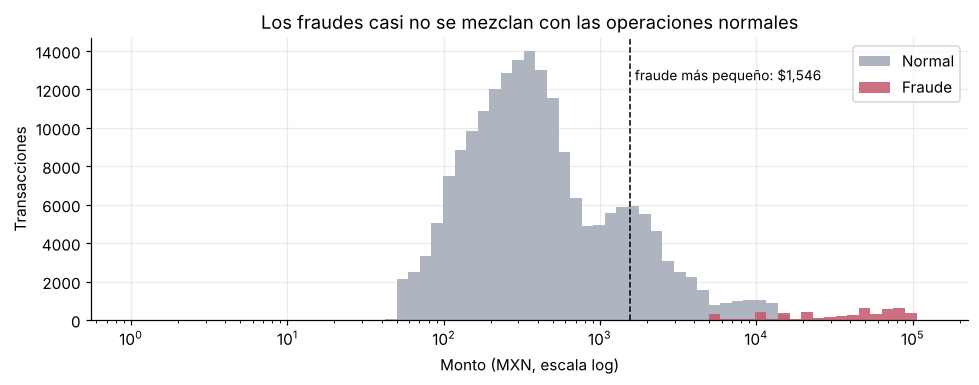

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.logspace(0, 5.1, 70)
ax.hist(normales["monto"], bins=bins, color=GRIS, alpha=.8, label="Normal")
ax.hist(fraudes["monto"], bins=bins, color=ROJO, alpha=.85, label="Fraude")
ax.axvline(fraudes["monto"].min(), color="k", ls="--", lw=1)
ax.text(fraudes["monto"].min()*1.08, ax.get_ylim()[1]*.85,
        f"fraude más pequeño: ${fraudes['monto'].min():,.0f}", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("Monto (MXN, escala log)"); ax.set_ylabel("Transacciones")
ax.set_title("Los fraudes casi no se mezclan con las operaciones normales")
ax.legend(); plt.tight_layout(); plt.show()

In [6]:
def evaluar_regla(mascara, nombre):
    tp = (mascara & (df["y"] == 1)).sum()
    marcadas = mascara.sum()
    return {"regla": nombre,
            "transacciones marcadas": marcadas,
            "% marcado": marcadas / len(df),
            "recall (fraudes atrapados)": tp / df["y"].sum(),
            "precisión": tp / marcadas if marcadas else 0}

reglas = pd.DataFrame([
    evaluar_regla(df["monto"] > 1_500, "monto > $1,500"),
    evaluar_regla(df["monto"] > 5_000, "monto > $5,000"),
    evaluar_regla(df["monto"] > 10_000, "monto > $10,000"),
])
reglas

,regla,transacciones marcadas,% marcado,recall (fraudes atrapados),precisión
0,"monto > $1,500",36660,0.183,1.000,0.139
1,"monto > $5,000",10617,0.053,0.926,0.443
2,"monto > $10,000",6310,0.032,0.827,0.665


**Una sola regla, `monto > $1,500`, atrapa el 100% de los fraudes.** Ningún fraude del conjunto
es menor a $1,545. En un banco real los defraudadores prueban primero con montos pequeños
justamente para no activar reglas así.

### Otros rastros del generador de datos

En las operaciones normales el saldo cuadra: `saldo_previo − monto = saldo_posterior`.
En los fraudes, casi nunca. Es un artefacto de cómo se generaron los datos, no un patrón de fraude.

In [7]:
descuadre = (df["saldo_previo"] - df["monto"] - df["saldo_posterior"]).abs() > 1
pd.DataFrame({"% con saldo que no cuadra": descuadre.groupby(df["y"]).mean()}) \
  .rename(index={0: "normales", 1: "fraudes"})

,% con saldo que no cuadra
y,
normales,0.117
fraudes,0.699


Si se agregara una variable "el saldo no cuadra", el modelo la usaría y la métrica subiría aún más,
por una razón que no existe en el mundo real. El modelo original no la usó; bien.

### La bandera de horario no apunta a donde está el fraude

El análisis original definió como "horario de riesgo" de 00:00 a 04:59. Veamos la tasa real por hora.

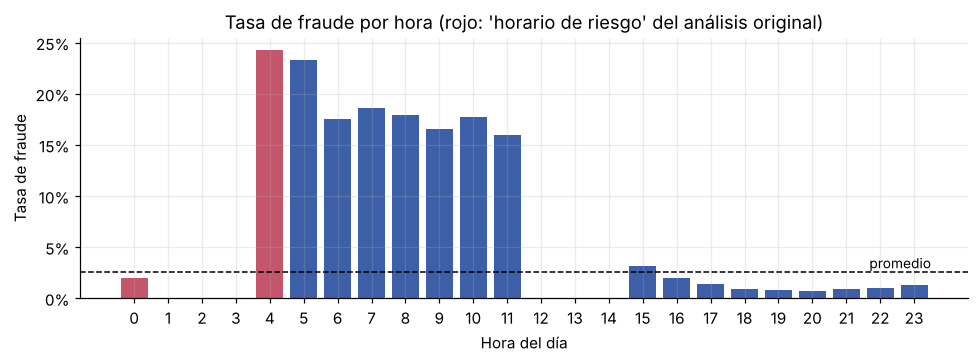

hora,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
tasa,0.020,0.000,0.000,0.000,0.242,0.233,0.175,0.186,0.179,0.166,...,0.000,0.031,0.019,0.014,0.009,0.008,0.007,0.009,0.010,0.013
fraudes,219.000,0.000,0.000,0.000,505.000,501.000,336.000,371.000,357.000,329.000,...,0.000,197.000,210.000,206.000,179.000,187.000,214.000,216.000,193.000,192.000
total,"10,846.000","1,655.000","1,629.000","1,619.000","2,083.000","2,154.000","1,921.000","1,997.000","1,995.000","1,987.000",...,"1,622.000","6,283.000","10,880.000","14,975.000","19,604.000","24,000.000","28,598.000","24,191.000","19,433.000","15,252.000"


In [8]:
por_hora = df.groupby("hora")["y"].agg(tasa="mean", fraudes="sum", total="count")
fig, ax = plt.subplots(figsize=(9, 3.4))
colores = [ROJO if 0 <= h <= 4 else AZUL for h in por_hora.index]
ax.bar(por_hora.index, por_hora["tasa"], color=colores)
ax.axhline(df["y"].mean(), color="k", ls="--", lw=1)
ax.text(23.5, df["y"].mean()+.004, "promedio", ha="right", fontsize=9)
ax.set_xticks(range(24)); ax.set_xlabel("Hora del día"); ax.set_ylabel("Tasa de fraude")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Tasa de fraude por hora (rojo: 'horario de riesgo' del análisis original)")
plt.tight_layout(); plt.show()
por_hora.T

El fraude se concentra entre las **04:00 y las 11:59**, no de 00:00 a 04:59: de 01:00 a 03:59 no hay
un solo fraude. Por eso la regla de "tres banderas" (horario + tipo + canal) que se usó como línea base
**casi no es mejor que el azar**:

In [9]:
df["feat_horario_riesgo"] = df["hora"].between(0, 4).astype(int)
df["feat_tipo_riesgo"] = df["tipo_transaccion"].isin(["Transferencia", "Transferencia internacional"]).astype(int)
df["feat_canal_riesgo"] = df["canal_transaccion"].isin(["Sucursal bancaria", "Web", "App movil"]).astype(int)
df["feat_perfil_riesgo_completo"] = (df["feat_horario_riesgo"] & df["feat_tipo_riesgo"] & df["feat_canal_riesgo"]).astype(int)
df["feat_log_monto"] = np.log1p(df["monto"])

pd.DataFrame([
    evaluar_regla(df["feat_perfil_riesgo_completo"] == 1, "3 banderas (línea base original)"),
    evaluar_regla(pd.Series(np.random.default_rng(0).random(len(df)) < .0335, index=df.index), "al azar, mismo volumen que el modelo"),
])

,regla,transacciones marcadas,% marcado,recall (fraudes atrapados),precisión
0,3 banderas (línea base original),4808,0.024,0.041,0.044
1,"al azar, mismo volumen que el modelo",6645,0.033,0.032,0.025


## 3. Réplica del modelo original

Mismos atributos que el notebook de Spark: las banderas, el log del monto, la razón monto/promedio
del tipo, el monto, y siete variables categóricas en one-hot. Random Forest de 100 árboles,
profundidad 10 y peso de clase 38.38 para los fraudes.

**Corrección de una fuga pequeña:** en el original, el promedio por tipo de transacción se calculó con
*todos* los datos, incluida la prueba. Aquí se calcula solo con entrenamiento.

In [10]:
CATEGORICAS = ["tipo_transaccion", "canal_transaccion", "categoria", "divisa", "estatus", "medio_pago", "ciudad"]
BANDERAS = ["feat_horario_riesgo", "feat_tipo_riesgo", "feat_canal_riesgo", "feat_perfil_riesgo_completo"]
MONTO = ["feat_log_monto", "feat_ratio_monto_vs_tipo", "monto"]

def preparar(entreno, prueba, numericas, categoricas):
    """Calcula la razón monto/promedio con el entrenamiento y arma las matrices one-hot."""
    entreno, prueba = entreno.copy(), prueba.copy()
    promedio_tipo = entreno.groupby("tipo_transaccion")["monto"].mean()
    for t in (entreno, prueba):
        t["feat_ratio_monto_vs_tipo"] = t["monto"] / t["tipo_transaccion"].map(promedio_tipo)
    X_tr = pd.get_dummies(entreno[numericas + categoricas], columns=categoricas, dtype=float)
    X_te = pd.get_dummies(prueba[numericas + categoricas], columns=categoricas, dtype=float)
    X_te = X_te.reindex(columns=X_tr.columns, fill_value=0)   # categorías nuevas quedan en cero
    return X_tr, X_te

def bosque():
    return RandomForestClassifier(n_estimators=100, max_depth=10, class_weight={0: 1, 1: 38.38},
                                  n_jobs=-1, random_state=42)

PRESUPUESTO = 0.0335   # el equipo de riesgos revisa 3.35% de las transacciones (1,333 de 39,745 en el original)

def metricas(y, prob, nombre):
    k = int(round(PRESUPUESTO * len(y)))
    top = np.argsort(-prob)[:k]
    y = np.asarray(y)
    pred = prob >= .5
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"escenario": nombre,
            "PR-AUC": average_precision_score(y, prob),
            "ROC-AUC": roc_auc_score(y, prob),
            "recall (umbral 0.5)": tp / (tp + fn),
            "precisión (umbral 0.5)": tp / (tp + fp) if tp + fp else 0,
            f"recall revisando {PRESUPUESTO:.2%}": y[top].sum() / y.sum()}

entreno, prueba = train_test_split(df, test_size=.2, random_state=42, stratify=df["y"])
X_tr, X_te = preparar(entreno, prueba, BANDERAS + MONTO, CATEGORICAS)
modelo = bosque().fit(X_tr, entreno["y"])
prob_original = modelo.predict_proba(X_te)[:, 1]

resultados = [metricas(prueba["y"], prob_original, "Réplica del original (partición aleatoria)")]
pd.DataFrame(resultados)

,escenario,PR-AUC,ROC-AUC,recall (umbral 0.5),precisión (umbral 0.5),recall revisando 3.35%
0,Réplica del original (partición aleatoria),1.000,1.000,1.000,0.876,1.000


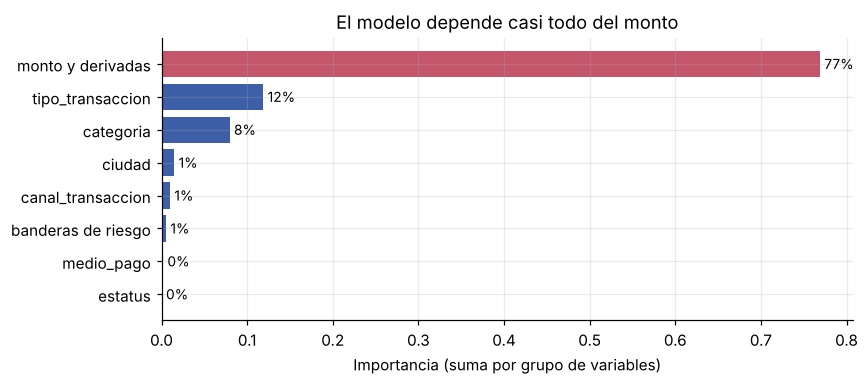

In [11]:
importancia = pd.Series(modelo.feature_importances_, index=X_tr.columns).sort_values(ascending=False)
def grupo(columna):
    """Junta las columnas one-hot con la variable de la que salieron."""
    if columna in MONTO:
        return "monto y derivadas"
    if columna in BANDERAS:
        return "banderas de riesgo"
    for c in CATEGORICAS:
        if columna.startswith(c + "_"):
            return c
    return columna

por_grupo = importancia.groupby(importancia.index.map(grupo)).sum().sort_values().tail(8)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(por_grupo.index, por_grupo.values, color=[ROJO if g == "monto y derivadas" else AZUL for g in por_grupo.index])
for i, v in enumerate(por_grupo.values):
    ax.text(v + .005, i, f"{v:.0%}", va="center", fontsize=9)
ax.set_xlabel("Importancia (suma por grupo de variables)")
ax.set_title("El modelo depende casi todo del monto")
plt.tight_layout(); plt.show()

## 4. Pruebas de ablación: quitar piezas y ver qué se cae

Si el modelo "entiende" el fraude, debería sostenerse parcialmente sin el monto.
Si solo copió la regla del generador, el monto solo debería bastar.

In [12]:
escenarios = {
    "Solo el monto": (["monto"], []),
    "Todo menos el monto y sus derivadas": (BANDERAS, CATEGORICAS),
    "Sin monto, sin tipo ni categoría": (["feat_horario_riesgo", "feat_canal_riesgo"],
                                         ["canal_transaccion", "estatus", "medio_pago", "ciudad"]),
}
for nombre, (num, cat) in escenarios.items():
    a, b = preparar(entreno, prueba, num, cat)
    p = bosque().fit(a, entreno["y"]).predict_proba(b)[:, 1]
    resultados.append(metricas(prueba["y"], p, nombre))

# Línea base honesta: regresión logística con los mismos atributos
a, b = preparar(entreno, prueba, ["feat_log_monto", "feat_ratio_monto_vs_tipo"] + BANDERAS, CATEGORICAS)
p = LogisticRegression(max_iter=3000, class_weight="balanced").fit(a, entreno["y"]).predict_proba(b)[:, 1]
resultados.append(metricas(prueba["y"], p, "Regresión logística (mismos atributos)"))

tabla = pd.DataFrame(resultados).set_index("escenario")
tabla

,PR-AUC,ROC-AUC,recall (umbral 0.5),precisión (umbral 0.5),recall revisando 3.35%
escenario,,,,,
Réplica del original (partición aleatoria),1.000,1.000,1.000,0.876,1.000
Solo el monto,0.964,0.997,0.965,0.529,0.944
Todo menos el monto y sus derivadas,0.230,0.935,0.898,0.119,0.339
"Sin monto, sin tipo ni categoría",0.068,0.715,0.567,0.061,0.139
Regresión logística (mismos atributos),0.959,0.998,0.959,0.478,0.926


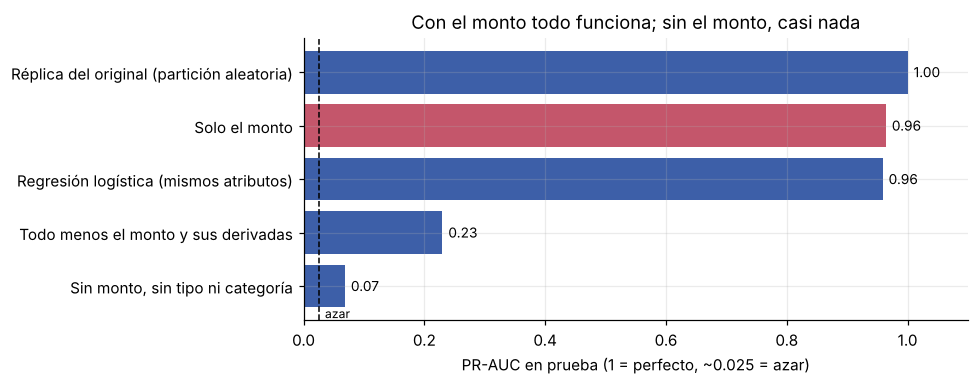

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.6))
orden = tabla["PR-AUC"].sort_values()
ax.barh(orden.index, orden.values, color=[ROJO if "monto" in i.lower() and "menos" not in i.lower() and "sin" not in i.lower() else AZUL for i in orden.index])
for i, v in enumerate(orden.values):
    ax.text(v + .01, i, f"{v:.2f}", va="center", fontsize=9)
ax.axvline(df["y"].mean(), color="k", ls="--", lw=1)
ax.text(df["y"].mean() + .01, -.6, "azar", fontsize=8)
ax.set_xlim(0, 1.1); ax.set_xlabel("PR-AUC en prueba (1 = perfecto, ~0.025 = azar)")
ax.set_title("Con el monto todo funciona; sin el monto, casi nada")
plt.tight_layout(); plt.show()

**Lectura:**
- El monto, solo, ya da un PR-AUC cercano a 1. Todo lo demás aporta muy poco.
- Sin el monto, el modelo cae a un PR-AUC bajo: con el mismo presupuesto de revisión atrapa una
  fracción de los fraudes.
- Una regresión logística, mucho más simple, queda muy cerca del Random Forest.

El 100% no mide la calidad del modelo. Mide que **el generador de datos puso todos los fraudes por
encima de $1,545**.

## 5. Validación temporal

En producción el modelo se entrena con el pasado y se usa en el futuro. La partición aleatoria mezcla
meses. Probemos entrenar hasta julio de 2025 y evaluar de agosto a diciembre de 2025.

In [14]:
corte = pd.Timestamp("2025-08-01")
entreno_t, prueba_t = df[df["fecha_dt"] < corte], df[df["fecha_dt"] >= corte]
a, b = preparar(entreno_t, prueba_t, BANDERAS + MONTO, CATEGORICAS)
p = bosque().fit(a, entreno_t["y"]).predict_proba(b)[:, 1]
temporal = metricas(prueba_t["y"], p, "Réplica con partición temporal")
print(f"Entreno: {len(entreno_t):,} filas | Prueba: {len(prueba_t):,} filas")

tasa_mensual = df.groupby(df["fecha_dt"].dt.to_period("M"))["y"].mean()
print(f"Tasa de fraude mensual: mínimo {tasa_mensual.min():.2%}, máximo {tasa_mensual.max():.2%}")
pd.DataFrame([tabla.loc["Réplica del original (partición aleatoria)"].rename("aleatoria"),
              pd.Series(temporal).drop("escenario").rename("temporal")])

Entreno: 158,461 filas | Prueba: 41,539 filas
Tasa de fraude mensual: mínimo 2.24%, máximo 2.74%


,PR-AUC,ROC-AUC,recall (umbral 0.5),precisión (umbral 0.5),recall revisando 3.35%
aleatoria,1.000,1.000,1.000,0.876,1.000
temporal,1.000,1.000,1.000,0.785,1.000


Aquí no cambia nada, y eso también es un hallazgo: **la tasa de fraude es plana todos los meses**.
En datos reales el fraude cambia de un mes a otro porque los defraudadores se adaptan. Por eso, en el
notebook con datos reales, la partición temporal sí importa.

## 6. ¿El modelo del notebook es el que corre en Kafka?

El flujo en vivo tiene tres piezas: `productor.py` genera eventos, `consumidor.py` calcula los
atributos y aplica el modelo. Comparando el código con los datos de entrenamiento:

| Campo | En entrenamiento | En el productor de Kafka |
|---|---|---|
| `tipo_transaccion` | "Transferencia", "Pago de nomina"… | "compra", "retiro", "transferencia", "deposito" |
| `canal_transaccion` | "App movil", "Web", "Sucursal bancaria"… | "movil_ios", "web_chrome", "cajero_automatico"… |
| `estatus` | "Completada", "Rechazada"… | "aprobada", "declinada" |
| `ciudad` | 6 ciudades de México | ciudades inventadas por Faker en España |
| `monto` | hasta $99,999; fraudes desde $1,545 | uniforme entre $5 y $5,000 |
| `categoria`, `medio_pago` | valores reales | se rellenan con un valor fijo en el consumidor |
| promedio por tipo | calculado de los datos | escrito a mano con un comentario "¡debes usar tus promedios reales!" |

Simulemos 20,000 eventos tal como los genera el productor y pasémoslos por el mismo modelo.

In [15]:
rng = np.random.default_rng(7)
n = 20_000
evento = pd.DataFrame({
    "monto": rng.uniform(5, 5000, n).round(2),
    "tipo_transaccion": rng.choice(["compra", "retiro", "transferencia", "deposito"], n),
    "canal_transaccion": rng.choice(["movil_ios", "movil_android", "web_chrome", "cajero_automatico"], n),
    "estatus": rng.choice(["aprobada", "declinada"], n),
    "ciudad": rng.choice(["Valencia", "Sevilla", "Bilbao", "Zaragoza", "Málaga"], n),
    "hora": rng.integers(0, 24, n),
})
# Mismo feature engineering que consumidor.py
evento["categoria"] = np.where(evento["tipo_transaccion"] == "compra", "Consumo", "Transferencia per...")
evento["divisa"] = "MXN"
evento["medio_pago"] = np.where(evento["canal_transaccion"] == "cajero_automatico", "Tarjeta debito", "App movil")
evento["feat_horario_riesgo"] = evento["hora"].between(0, 4).astype(int)
evento["feat_tipo_riesgo"] = evento["tipo_transaccion"].isin(["transferencia", "Transferencia internacional"]).astype(int)
evento["feat_canal_riesgo"] = evento["canal_transaccion"].isin(["Sucursal bancaria", "web_chrome", "movil_ios", "movil_android"]).astype(int)
evento["feat_perfil_riesgo_completo"] = (evento["feat_horario_riesgo"] & evento["feat_tipo_riesgo"] & evento["feat_canal_riesgo"]).astype(int)
evento["feat_log_monto"] = np.log1p(evento["monto"])
promedio_a_mano = {"compra": 500.0, "retiro": 1500.0, "transferencia": 8000.0, "deposito": 4000.0}
evento["feat_ratio_monto_vs_tipo"] = evento["monto"] / evento["tipo_transaccion"].map(promedio_a_mano)

X_vivo = pd.get_dummies(evento[BANDERAS + MONTO + CATEGORICAS], columns=CATEGORICAS, dtype=float) \
           .reindex(columns=X_tr.columns, fill_value=0)
prob_vivo = modelo.predict_proba(X_vivo)[:, 1]

cobertura = {c: evento[c].isin(entreno[c].unique()).mean() for c in ["tipo_transaccion", "canal_transaccion", "estatus", "ciudad", "categoria", "medio_pago"]}
print("Porcentaje de eventos cuyo valor existe en el entrenamiento:")
for c, v in cobertura.items():
    print(f"  {c:20s} {v:6.1%}")
print(f"\nEventos marcados como fraude (prob ≥ 0.5): {(prob_vivo >= .5).mean():.1%}")
print(f"En entrenamiento, la tasa real era:          {df['y'].mean():.1%}")

Porcentaje de eventos cuyo valor existe en el entrenamiento:
  tipo_transaccion       0.0%
  canal_transaccion      0.0%
  estatus                0.0%
  ciudad                 0.0%
  categoria             24.3%
  medio_pago            24.6%

Eventos marcados como fraude (prob ≥ 0.5): 10.2%
En entrenamiento, la tasa real era:          2.5%


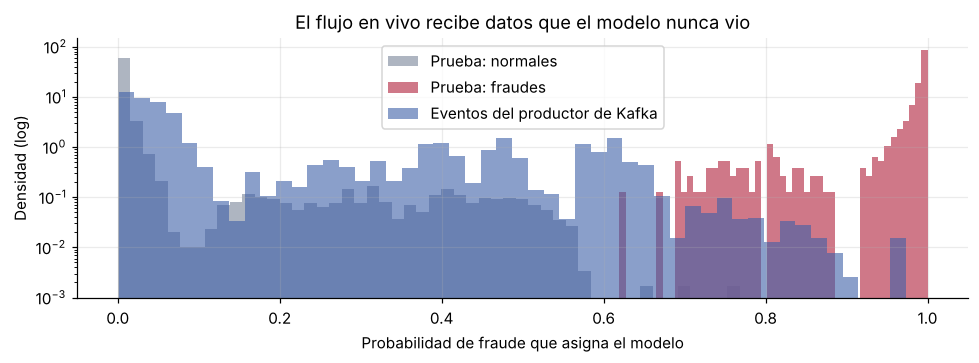

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(prob_original[prueba["y"].values == 0], bins=50, color=GRIS, alpha=.8, label="Prueba: normales", density=True)
ax.hist(prob_original[prueba["y"].values == 1], bins=50, color=ROJO, alpha=.8, label="Prueba: fraudes", density=True)
ax.hist(prob_vivo, bins=50, color=AZUL, alpha=.6, label="Eventos del productor de Kafka", density=True)
ax.set_yscale("log"); ax.set_xlabel("Probabilidad de fraude que asigna el modelo"); ax.set_ylabel("Densidad (log)")
ax.set_title("El flujo en vivo recibe datos que el modelo nunca vio")
ax.legend(); plt.tight_layout(); plt.show()

**Lectura:** ninguno de los valores categóricos del productor existe en el entrenamiento, el monto
nunca pasa de $5,000 y los promedios por tipo son inventados. El modelo funciona en el notebook,
pero lo que ve en el flujo de Kafka es otra distribución. A esto se le llama **desfase entre
entrenamiento y servicio** (*training-serving skew*), y es de las fallas más comunes al llevar un
modelo a producción.

Además, el modelo marca como fraude cerca del **10% de los eventos simulados**, cuatro veces la tasa
histórica, aunque el productor no genera ningún patrón de fraude. Esas alertas no significan nada.

Cómo se arregla: un solo módulo de atributos que usen tanto el entrenamiento como el consumidor,
un productor que genere el mismo esquema que los datos históricos, y una validación de esquema
(por ejemplo, rechazar o registrar categorías desconocidas) antes de puntuar.

## 7. ¿Dónde poner el umbral? Pensarlo en dinero

El umbral de 0.5 es arbitrario. El negocio necesita comparar dos costos:

- **Revisar** una transacción cuesta tiempo de analista. Supuesto: **$50 MXN** por revisión (unos 10 minutos).
- **Dejar pasar** un fraude cuesta su monto.

Para cada umbral, costo total = (transacciones revisadas × $50) + (monto de los fraudes no detectados).
Supuestos simples y explícitos; con datos reales del banco se reemplazan.

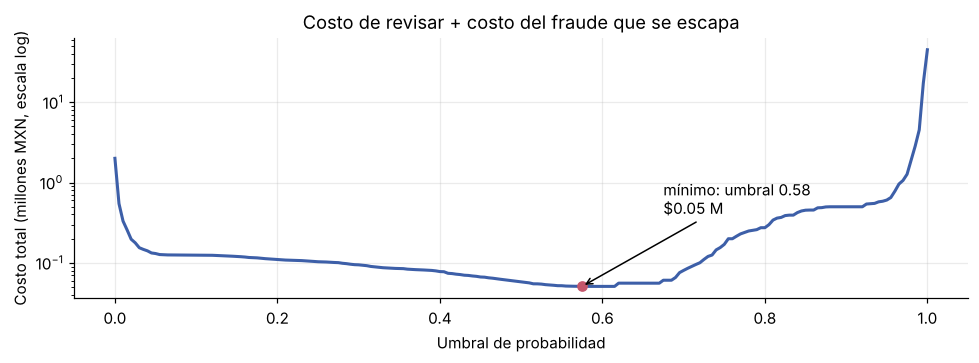

No revisar nada:   $45.38 M en fraude perdido
Revisar todo:      $2.00 M en revisiones
Con el modelo:     $0.05 M (umbral 0.58, revisando 2.55% de las transacciones)


In [17]:
COSTO_REVISION = 50
y_te = prueba["y"].values
monto_te = prueba["monto"].values

umbrales = np.linspace(0, 1, 201)
costos = []
for u in umbrales:
    revisa = prob_original >= u
    costo = revisa.sum() * COSTO_REVISION + monto_te[(y_te == 1) & ~revisa].sum()
    costos.append(costo)
costos = np.array(costos)
mejor = umbrales[costos.argmin()]

no_revisar = monto_te[y_te == 1].sum()
revisar_todo = len(y_te) * COSTO_REVISION

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(umbrales, costos / 1e6, color=AZUL, lw=2)
ax.scatter([mejor], [costos.min() / 1e6], color=ROJO, zorder=3)
ax.annotate(f"mínimo: umbral {mejor:.2f}\n${costos.min()/1e6:.2f} M", (mejor, costos.min()/1e6),
            xytext=(mejor + .1, costos.min()/1e6 * 8), arrowprops=dict(arrowstyle="->"))
ax.set_yscale("log")
ax.set_xlabel("Umbral de probabilidad"); ax.set_ylabel("Costo total (millones MXN, escala log)")
ax.set_title("Costo de revisar + costo del fraude que se escapa")
plt.tight_layout(); plt.show()

print(f"No revisar nada:   ${no_revisar/1e6:,.2f} M en fraude perdido")
print(f"Revisar todo:      ${revisar_todo/1e6:,.2f} M en revisiones")
print(f"Con el modelo:     ${costos.min()/1e6:,.2f} M (umbral {mejor:.2f}, revisando {(prob_original>=mejor).mean():.2%} de las transacciones)")

Con estos datos el ahorro es enorme porque el problema es fácil. La parte valiosa es el **método**:
el umbral sale de una decisión de negocio explícita, no del 0.5 por defecto.

## 8. Conclusiones

| Pregunta | Respuesta |
|---|---|
| ¿Qué tan difícil es el problema? | Muy fácil: `monto > $1,500` atrapa el 100% de los fraudes. |
| ¿De qué depende el modelo? | Del monto. Sin él, el PR-AUC se desploma. |
| ¿Hay fuga? | Una pequeña (el promedio por tipo usaba datos de prueba) y artefactos del generador (saldos que no cuadran). |
| ¿Las reglas del EDA eran correctas? | La bandera de horario apuntaba a 00:00–04:59; el fraude está entre 04:00 y 11:59. |
| ¿El flujo de Kafka usa el mismo modelo? | Sí, pero con datos de otra forma: ninguna categoría coincide. |
| ¿Dónde va el umbral? | Donde el costo total es mínimo, con supuestos de costo explícitos. |

**Qué cambiar en el proyecto:**
1. Presentar el 100% como lo que es: el modelo recuperó la regla del generador.
2. Corregir la bandera de horario y calcular los promedios solo con entrenamiento.
3. Unificar el cálculo de atributos entre el notebook y `consumidor.py`.
4. Probar el mismo flujo con datos reales (siguiente notebook: IEEE-CIS).